In [ ]:
from typing import Literal
import numpy as np
from matplotlib import pyplot as plt

In [ ]:
class My_LinearRegression():
  def __init__(self) -> None:
    self._coer = None

  def fit(self, X_train, y_train, method:  Literal["closed", "gd"] = "closed", num_epochs = 100, lr = 1e-3):
    if method == "closed":
      X_T = X_train.T
      self._coef = np.linalg.inv(X_T @ X_train) @ X_T @ y_train
    else:
      self._coef = self._sgd(X_train, y_train, num_epochs, lr)
  def predict(self, X_test: np.ndarray) -> np.ndarray:
    pred = X_test @ self._coef
    return pred

  def score(self, X_test, y_test, metric: Literal["MSE", "MAE", "RSME"]) -> float:
    y_pred = self.predict(X_test = X_test)
    if metric == "MSE":
      return np.mean((y_pred - y_test) ** 2)
    elif metric == "MAE":
      return np.mean(np.abs(y_pred - y_test))
    else:
      return np.sqrt(np.mean((y_pred - y_test)))



  def _sgd(self, X_train, y_train, num_epochs, lr) -> np.ndarray:
    coef_norms = [0]
    coef_ = np.zeros(len(X_train[0]))
    for  epoch in range(num_epochs):
      for n in range(len(coef_)):
        coef_ = coef_ - lr * 2 * ((np.dot(coef_, X_train[n]) - y_train[n]) * X_train[n])

    coef_norms.append(np.linalg.norm(coef_))
    plt.plot(coef_norms)
    plt.xlabel("epochs")
    plt.ylabel("Norm of Coefficients")
    plt.show()

    return coef_

In [ ]:
np.random.seed(42)

d = 5
n_train = 200
n_test = 20


theta_star = np.random.rand(d)
print(f"GT Values are: {theta_star}")


X_train = np.random.normal(size = (n_train, d - 1), loc = 5, scale = 2)
y_train = theta_star[0] + X_train @ theta_star[1:] + np.random.normal(size = n_train, loc = 0, scale = 0.5)


X_test = np.random.normal(size = (n_test, d - 1), loc = 5, scale = 2)
y_test = theta_star[0] + X_test @ theta_star[1:] + np.random.normal(size = n_test, loc = 0, scale = 0.5)

GT Values are: [0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]


In [ ]:
def add_bais(X: np.ndarray) -> np.ndarray:
  ones = np.ones((X.shape[0], 1))
  return np.concatenate((ones, X), axis = 1)

In [ ]:
def fit_model(X_train, y_train, X_test, y_test, algorithm: Literal["closed", "gd"], metric:str) -> LinearRegression:
  updated_X_train = add_bais(X_train)
  updated_X_test = add_bais(X_test)
  model = LinearRegression()
  model.fit(X_train = updated_X_train, y_train = y_train, method = algorithm, num_epochs = 100, lr = 1e-3)

  y_preds = model.predict(X_test = updated_X_test)
  performance = model.score(X_test= updated_X_test, y_test = y_test, metric = metric)
  print(f"Performance of the {algorithm} with {metric} metric is {performance}")

  plt.scatter(y_test, y_preds)
  plt.plot(y_test,y_test,color = "red")
  plt.xlabel("y_test")
  plt.ylabel("y_pred")
  plt.title("Preds vs. GT")
  plt.show()
  return model

Performance of the closed with MAE metric is 0.4249599849604698


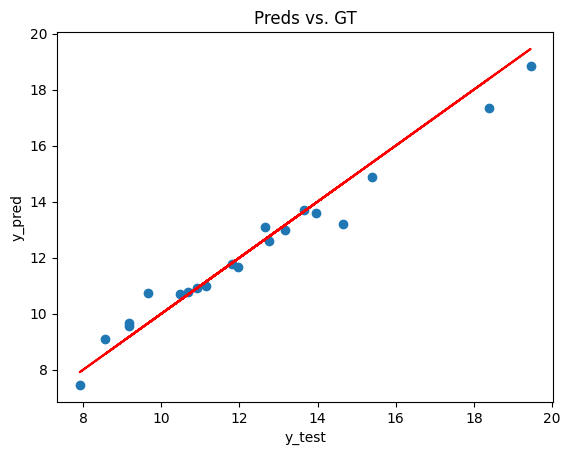

[0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]
[0.51243571 0.93401875 0.72945915 0.59396022 0.15246632]


In [ ]:
metric = "MAE"
algorithm = "closed"
closed_form_model = fit_model(X_train=X_train, y_train=y_train,X_test=X_test, y_test=y_test, algorithm=algorithm, metric=metric)
print(theta_star)
print(closed_form_model._coef)

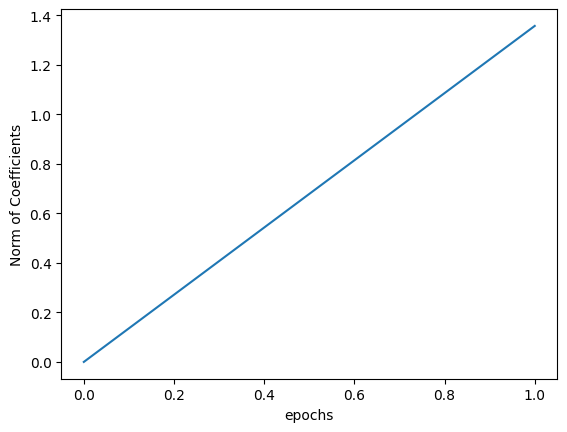

Performance of the gd with MSE metric is 0.4937530491610299


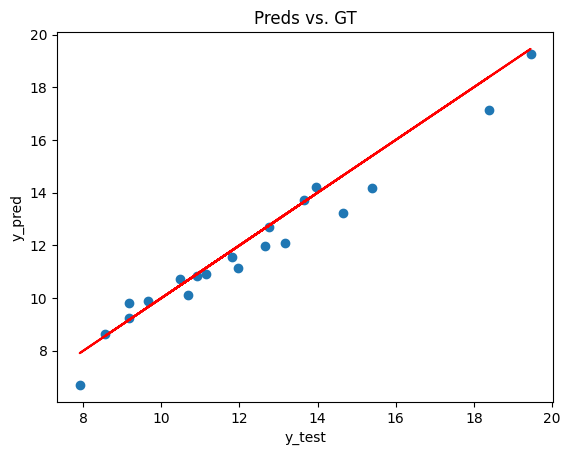

[0.37454012 0.95071431 0.73199394 0.59865848 0.15601864]
[0.06908363 0.94916172 0.57826213 0.75711369 0.16527093]


In [ ]:
metric = "MSE"
algorithm = "gd"
gd_model = fit_model(X_train=X_train, y_train=y_train,X_test=X_test, y_test=y_test, algorithm=algorithm, metric=metric)
print(theta_star)
print(gd_model._coef)

In [ ]:
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

In [ ]:
dataset = fetch_california_housing()

In [ ]:
X,y = dataset["data"], dataset["target"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state=42)

In [ ]:
model = LinearRegression()
model.fit(X_train,y_train)


LinearRegression()

In [ ]:
y_pred = model.predict(X_test)


<function matplotlib.pyplot.show(close=None, block=None)>

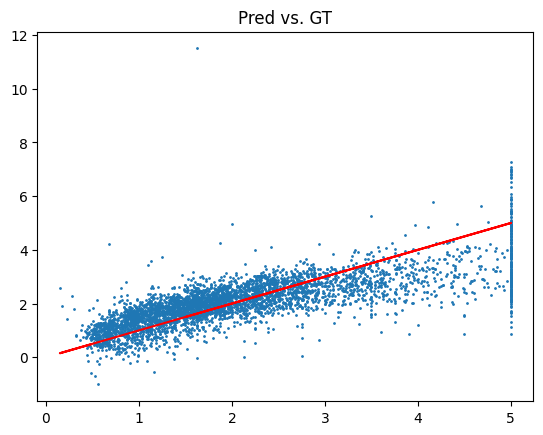

In [ ]:
plt.scatter(y_test, y_pred, s = 1)
plt.plot(y_test, y_test, color = "ches")
plt.xlabel = ("y_test")
plt.ylabel = (y_pred)
plt.title("Pred vs. GT")
plt.show